In [ ]:
# Kết nối Google Drive để đọc file dữ liệu
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập style cho biểu đồ đẹp hơn
sns.set_theme(style="whitegrid", palette="muted")
import warnings
warnings.filterwarnings('ignore')

# Đọc dữ liệu (code của bạn)
df = pd.read_csv('/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/Zomato Dataset.csv')

# Lưu ý nhỏ: Dữ liệu Zomato gốc thường bị dính khoảng trắng ở dữ liệu chuỗi (VD: ' Jam ' thay vì 'Jam').
# Bạn nên chạy dòng này để làm sạch sơ bộ trước khi EDA:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

In [ ]:
#Xem 5 dòng đầu tiên
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


1. DATA OVERVIEW

In [ ]:
#Số dòng và số cột của dataset
df.shape

(45584, 20)

In [ ]:
# Kiểm tra kiểu dữ liệu và số lượng giá trị bị thiếu
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  object 
 1   Delivery_person_ID           45584 non-null  object 
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  object 
 9   Time_Orderd                  43853 non-null  object 
 10  Time_Order_picked            45584 non-null  object 
 11  Weather_conditions           44968 non-null  object 
 12  Road_traffic_density         44983 non-null  object 
 13  Vehicle_conditio

2. Dữ liệu thiếu (Missing Values)

In [ ]:
# Tạo bảng thống kê tỷ lệ missing values
missing_data = df.isnull().sum()[df.isnull().sum() > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({
    'Số lượng thiếu': missing_data,
    'Tỷ lệ (%)': round((missing_data / len(df)) * 100, 2)
})
print(missing_df)

                         Số lượng thiếu  Tỷ lệ (%)
Delivery_person_Ratings            1908       4.19
Delivery_person_Age                1854       4.07
Time_Orderd                        1731       3.80
City                               1200       2.63
multiple_deliveries                 993       2.18
Weather_conditions                  616       1.35
Road_traffic_density                601       1.32
Festival                            228       0.50


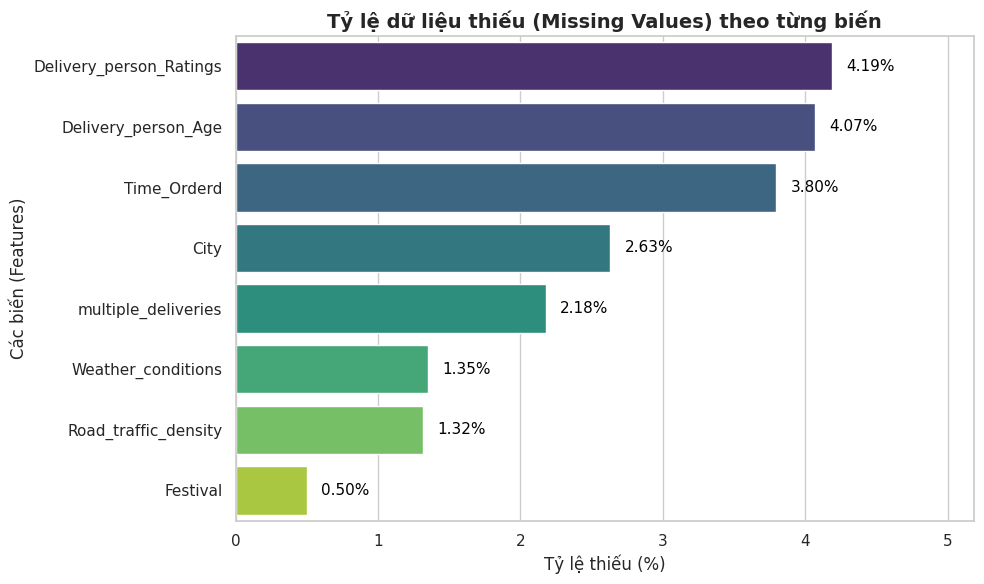

In [ ]:
# Tính toán số lượng và tỷ lệ % missing values (Chỉ lấy các cột có dữ liệu thiếu)
missing_data = df.isnull().sum()[df.isnull().sum() > 0].sort_values(ascending=False)
missing_percent = (missing_data / len(df)) * 100

# Thiết lập kích thước biểu đồ
plt.figure(figsize=(10, 6))

# Vẽ biểu đồ cột nằm ngang
ax = sns.barplot(x=missing_percent.values, y=missing_percent.index, palette="viridis")

# Thêm text % vào đuôi mỗi cột để hội đồng dễ đọc
for i, v in enumerate(missing_percent.values):
    ax.text(v + 0.1, i, f"{v:.2f}%", color='black', va='center', fontsize=11)

# Trang trí tiêu đề và trục
plt.title('Tỷ lệ dữ liệu thiếu (Missing Values) theo từng biến', fontsize=14, fontweight='bold')
plt.xlabel('Tỷ lệ thiếu (%)', fontsize=12)
plt.ylabel('Các biến (Features)', fontsize=12)

# Mở rộng trục X một chút để chữ % không bị lẹm ra ngoài viền
plt.xlim(0, max(missing_percent.values) + 1)

plt.tight_layout()
plt.show()

3. Giá trị ngoại lệ (Outliers) của biến định lượng liên tục

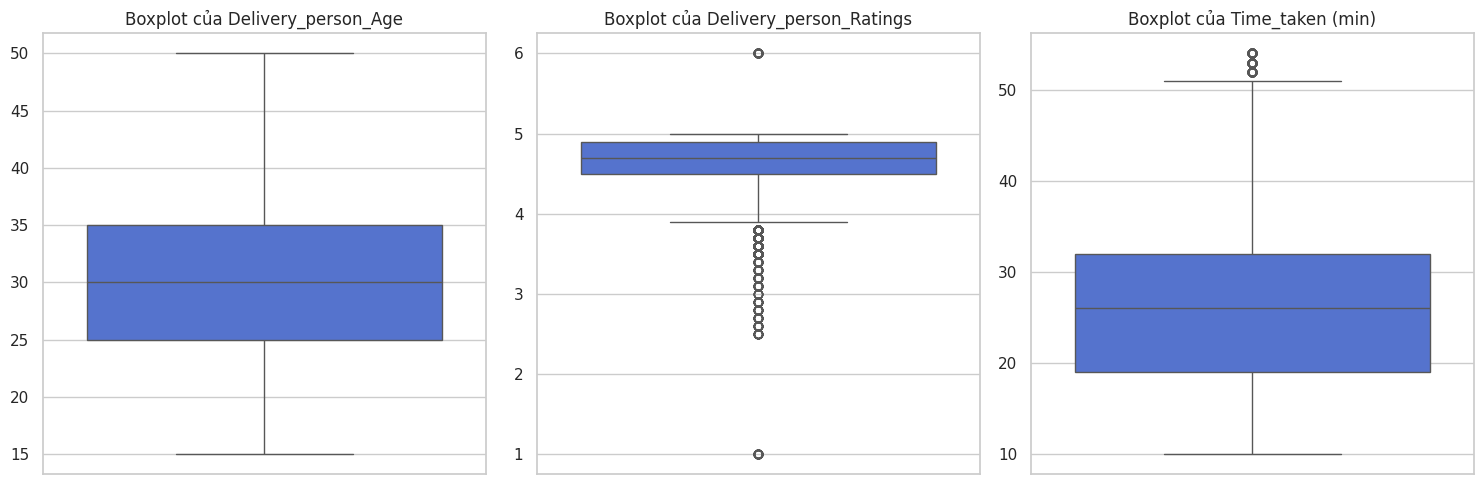

In [ ]:
# CHỈ VẼ BOXPLOT CHO 3 BIẾN LIÊN TỤC
continuous_cols =['Delivery_person_Age', 'Delivery_person_Ratings', 'Time_taken (min)']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(continuous_cols):
    sns.boxplot(data=df, y=col, ax=axes[i], color='royalblue')
    axes[i].set_title(f'Boxplot của {col}')
    axes[i].set_ylabel('')
plt.tight_layout()
plt.show()

In [ ]:
# Kiểm tra số lượng dòng bị lỗi 6 sao
error_ratings = df[df['Delivery_person_Ratings'] > 5]
print(f"Số lượng đơn hàng có Rating > 5: {len(error_ratings)}")
print(error_ratings['Delivery_person_Ratings'].unique())

Số lượng đơn hàng có Rating > 5: 53
[6.]


4. Phân tích đơn biến

4.1. Phân bố các biến số liên tục

In [ ]:
# Chọn 3 biến số liên tục cần thống kê
continuous_cols =['Delivery_person_Age', 'Delivery_person_Ratings', 'Time_taken (min)']

# Dùng hàm describe(), chuyển vị ma trận (.T) và chọn đúng 5 cột cần thiết
desc_table = df[continuous_cols].describe().T[['count', 'mean', 'std', 'min', 'max']]

# Làm tròn 2 chữ số thập phân cho đẹp
desc_table = desc_table.round(2)

# Hiển thị bảng
display(desc_table)

,count,mean,std,min,max
Delivery_person_Age,43730.0,29.57,5.82,15.0,50.0
Delivery_person_Ratings,43676.0,4.63,0.33,1.0,6.0
Time_taken (min),45584.0,26.29,9.38,10.0,54.0


In [ ]:
# 2. Vẽ Histogram (Phân bố) fig, axes = plt.subplots(1, 3, figsize=(15, 5)) for i, col in enumerate(continuous_cols): sns.histplot(data=df, x=col, kde=True, ax=axes[i], color='teal', bins=20) axes[i].set_title(f'Phân phối của {col}') plt.tight_layout() plt.show()

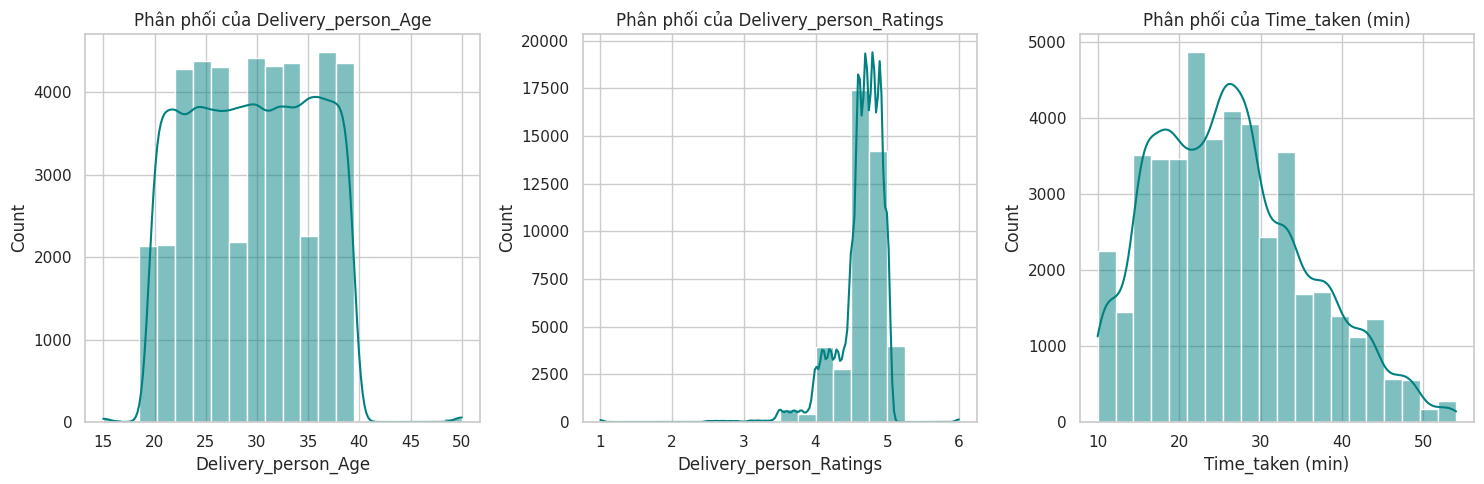

In [ ]:
# 2. Vẽ Histogram (Phân bố)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(continuous_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i], color='teal', bins=20)
    axes[i].set_title(f'Phân phối của {col}')
plt.tight_layout()
plt.show()

4.2. Phân bố các biến phân loại và biến thứ bậc

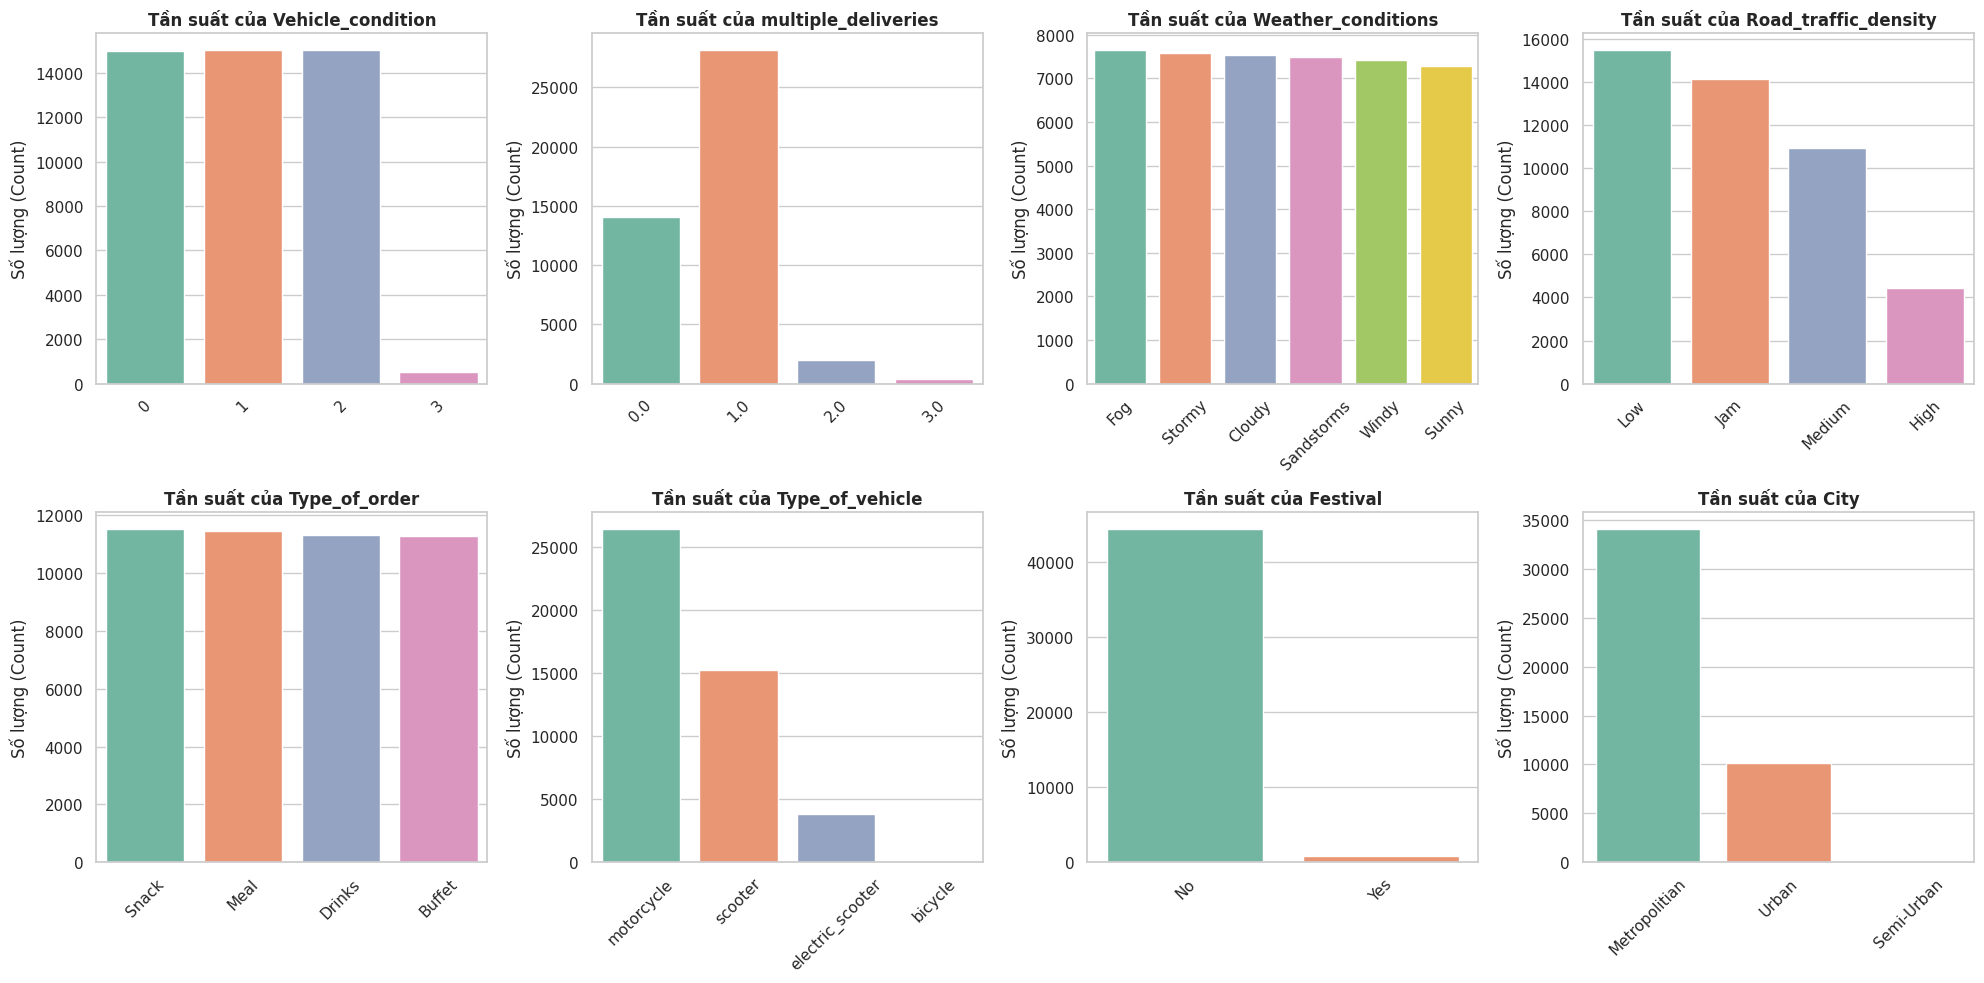

In [ ]:
# ĐÃ THÊM 'Festival' và 'City' VÀO LIST
cat_ordinal_cols =['Vehicle_condition', 'multiple_deliveries', 'Weather_conditions',
                    'Road_traffic_density', 'Type_of_order', 'Type_of_vehicle',
                    'Festival', 'City']

# Chuyển thành 2 hàng, 4 cột để vẽ đủ 8 biểu đồ
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(cat_ordinal_cols):
    # Nếu là biến thứ bậc (chứa số), sắp xếp theo giá trị 0, 1, 2, 3
    if col in['Vehicle_condition', 'multiple_deliveries']:
        order = sorted(df[col].dropna().unique())
    else:
        # Nếu là chữ, sắp xếp theo số lượng đếm giảm dần
        order = df[col].value_counts().index

    sns.countplot(data=df, x=col, ax=axes[i], palette='Set2', order=order)
    axes[i].set_title(f'Tần suất của {col}', fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Số lượng (Count)')

plt.tight_layout()
plt.show()

5. Phân tích đa biến: Động lực ảnh hưởng đến Thời gian giao hàng

Ảnh hưởng của Bối cảnh & Thuộc tính đến Thời gian giao

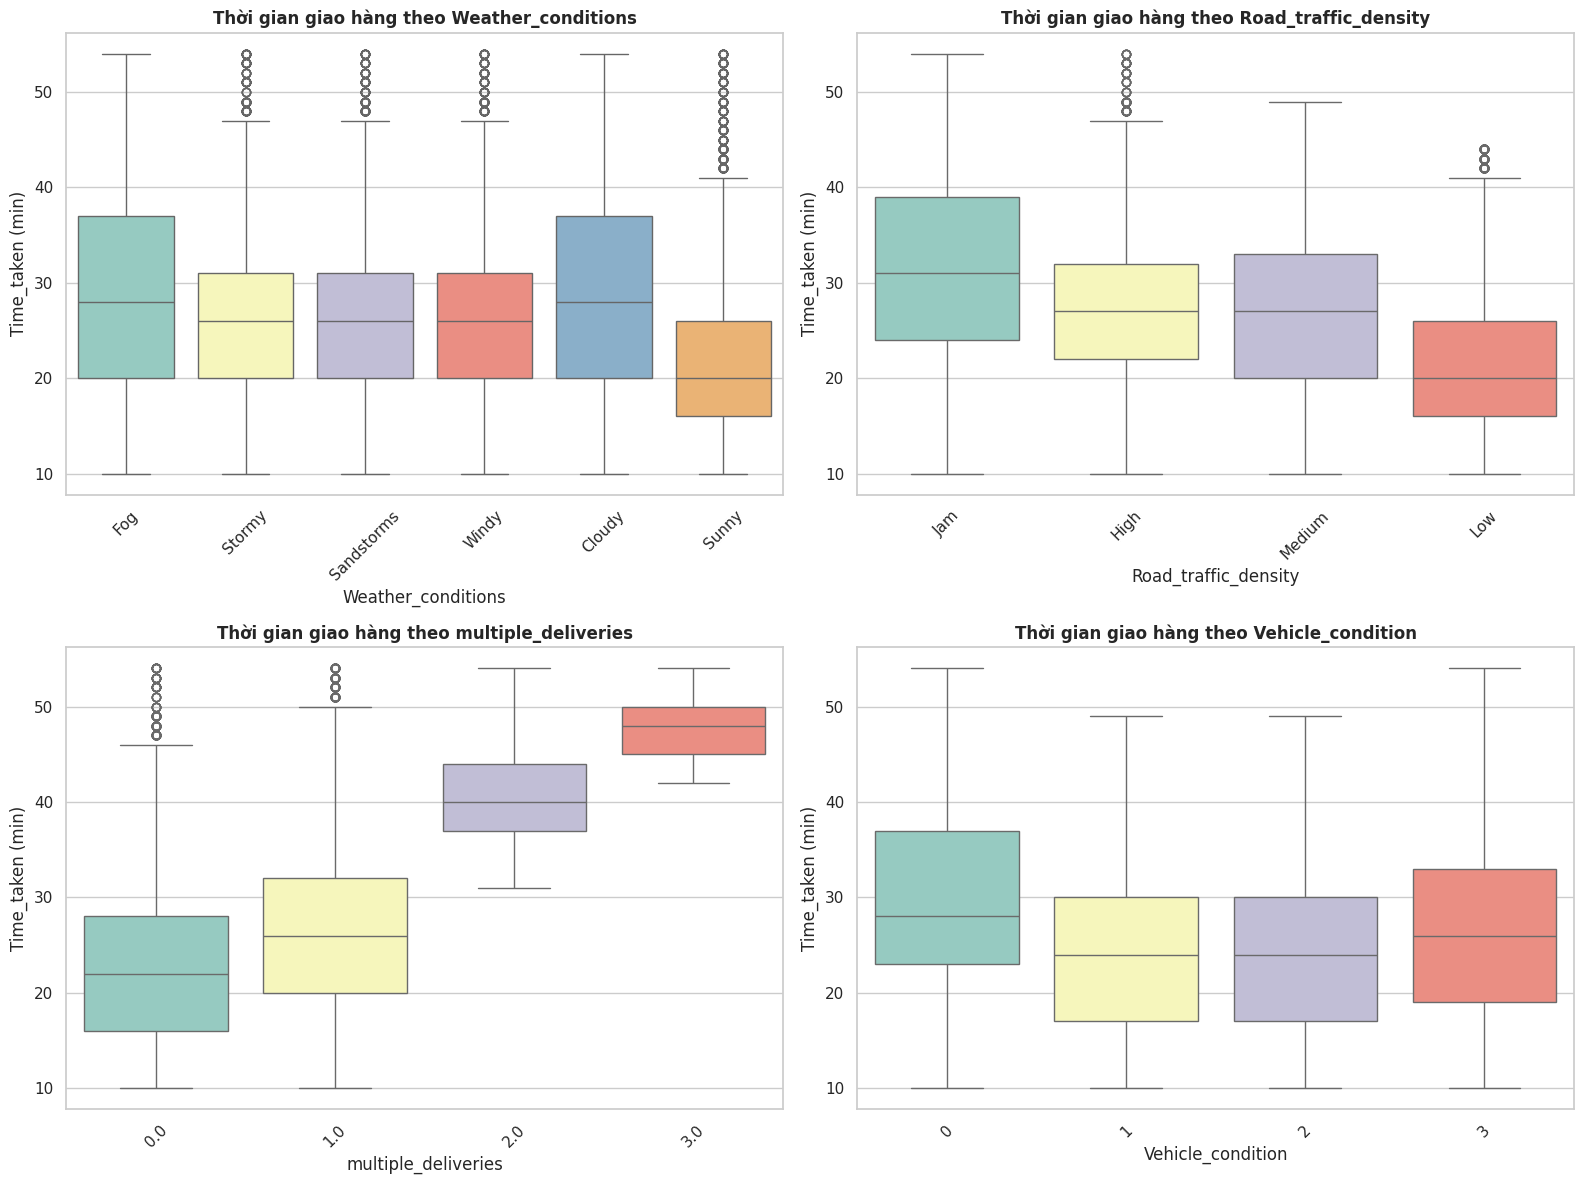

In [ ]:
features_to_plot =['Weather_conditions', 'Road_traffic_density', 'multiple_deliveries', 'Vehicle_condition']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.boxplot(data=df, x=col, y='Time_taken (min)', ax=axes[i], palette='Set3')
    axes[i].set_title(f'Thời gian giao hàng theo {col}', fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Phân tích yếu tố Không gian

In [ ]:
# 1. Chọn danh sách 4 cột không gian (tọa độ địa lý)
geo_cols = [
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude'
]

# 2. Chạy thống kê mô tả và làm tròn 4 chữ số thập phân (để dễ nhìn các mốc tọa độ nhỏ)
geo_stats = df[geo_cols].describe().round(4)

# 3. Hiển thị kết quả dưới dạng bảng đẹp trong Notebook
print("--- THỐNG KÊ MÔ TẢ CÁC BIẾN TỌA ĐỘ ĐỊA LÝ ---")
display(geo_stats)

--- THỐNG KÊ MÔ TẢ CÁC BIẾN TỌA ĐỘ ĐỊA LÝ ---


,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
count,45584.0000,45584.0000,45584.0000,45584.0000
mean,17.0179,70.2297,17.4655,70.8442
std,8.1857,22.8856,7.3356,21.1206
min,-30.9056,-88.3662,0.0100,0.0100
25%,12.9333,73.1700,12.9885,73.2800
50%,18.5514,75.8980,18.6339,76.0026
75%,22.7282,78.0441,22.7850,78.1070
max,30.9141,88.4335,31.0541,88.5635


In [ ]:
geo_cols = [
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude'
]

neg_rows = df[(df[geo_cols] < 0).any(axis=1)]

print("Số dòng có ít nhất 1 tọa độ âm:", len(neg_rows))

Số dòng có ít nhất 1 tọa độ âm: 431


In [ ]:
geo_cols = [
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude'
]

for col in geo_cols:
    count_neg = (df[col] < 0).sum()
    print(f"{col}: {count_neg} dòng có giá trị âm")

Restaurant_latitude: 431 dòng có giá trị âm
Restaurant_longitude: 162 dòng có giá trị âm
Delivery_location_latitude: 0 dòng có giá trị âm
Delivery_location_longitude: 0 dòng có giá trị âm


In [ ]:
import numpy as np

# 1. Dùng trị tuyệt đối (.abs()) cho TẤT CẢ 4 cột tọa độ để xóa dấu âm lỗi
df['Restaurant_latitude'] = df['Restaurant_latitude'].abs()
df['Restaurant_longitude'] = df['Restaurant_longitude'].abs()
df['Delivery_location_latitude'] = df['Delivery_location_latitude'].abs()
df['Delivery_location_longitude'] = df['Delivery_location_longitude'].abs()

# 2. Hàm Haversine (Hàm của bạn viết rất chuẩn rồi, giữ nguyên)
def haversine(lat1, lon1, lat2, lon2):
    R = 6371 # Bán kính trái đất
    lat1, lon1, lat2, lon2 = map(np.radians,[lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    c = 2*np.arcsin(np.sqrt(a))

    return R*c

# 3. Tính lại khoảng cách (Nhớ dùng 1 tên cột thôi cho đỡ rối, ví dụ: 'Distance_km')
df['Distance_km'] = haversine(
    df['Restaurant_latitude'],
    df['Restaurant_longitude'],
    df['Delivery_location_latitude'],
    df['Delivery_location_longitude']
)

# 4. Kiểm tra lại kết quả
print("Thống kê khoảng cách sau khi sửa lỗi dấu âm:")
print(df['Distance_km'].describe())

Thống kê khoảng cách sau khi sửa lỗi dấu âm:
count    45584.000000
mean         9.735119
std          5.608034
min          1.465067
25%          4.663345
50%          9.220148
75%         13.681492
max         20.969489
Name: Distance_km, dtype: float64


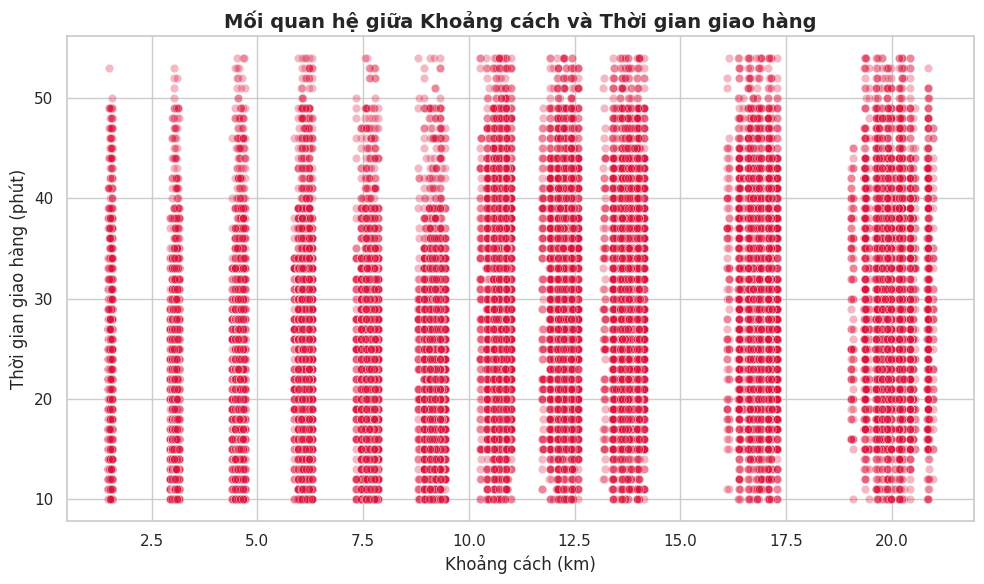

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Vẽ Scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Distance_km',
    y='Time_taken (min)',
    alpha=0.3,
    color='crimson'
)

plt.title('Mối quan hệ giữa Khoảng cách và Thời gian giao hàng', fontsize=14, fontweight='bold')
plt.xlabel('Khoảng cách (km)')
plt.ylabel('Thời gian giao hàng (phút)')

plt.tight_layout()
plt.show()

Phân tích yếu tố Thời gian

  Order_Date Time_Orderd     order_timestamp  Hour
0 2022-02-12       21:55 2022-02-12 21:55:00  21.0
1 2022-02-13       14:55 2022-02-13 14:55:00  14.0
2 2022-03-04       17:30 2022-03-04 17:30:00  17.0
3 2022-02-13       09:20 2022-02-13 09:20:00   9.0
4 2022-02-14       19:50 2022-02-14 19:50:00  19.0
    Hour  Time_taken (min)
0      8         19.580627
1      9         19.521469
2     10         19.480899
3     11         27.165158
4     12         26.775249
5     13         27.451705
6     14         27.543933
7     15         22.880559
8     16         23.012195
9     17         27.477559
10    18         27.289919
11    19         31.176301
12    20         31.178528
13    21         31.126286
14    22         22.416826
15    23         22.435314


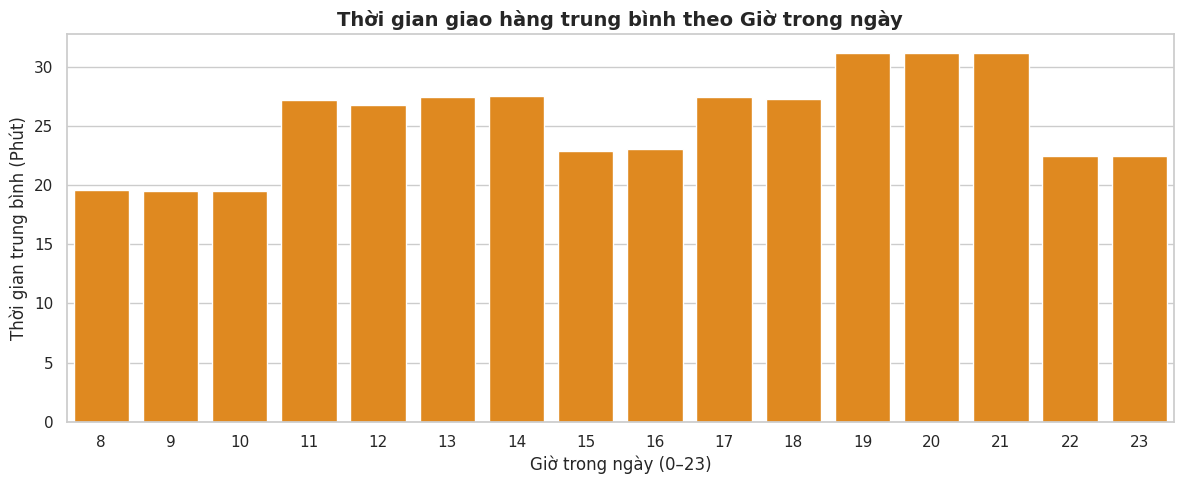

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Convert Order_Date sang datetime
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    dayfirst=True,
    errors="coerce"
)

# 2. Tạo timestamp cho thời điểm đặt hàng
df["order_timestamp"] = pd.to_datetime(
    df["Order_Date"].astype(str) + " " + df["Time_Orderd"].astype(str),
    errors="coerce"
)

# 3. Lấy giờ đặt hàng
df["Hour"] = df["order_timestamp"].dt.hour

# Kiểm tra
print(df[["Order_Date","Time_Orderd","order_timestamp","Hour"]].head())

# 4. Tính thời gian giao hàng trung bình theo giờ
hourly_time = (
    df.groupby("Hour")["Time_taken (min)"]
    .mean()
    .reset_index()
)

# 5. Ép kiểu về int để bỏ .0
hourly_time["Hour"] = hourly_time["Hour"].astype(int)

# 6. Sắp xếp theo giờ
hourly_time = hourly_time.sort_values("Hour")

print(hourly_time)

# 7. Vẽ biểu đồ
plt.figure(figsize=(12,5))

sns.barplot(
    data=hourly_time,
    x="Hour",
    y="Time_taken (min)",
    color="darkorange"
)

plt.title("Thời gian giao hàng trung bình theo Giờ trong ngày", fontsize=14, fontweight="bold")
plt.xlabel("Giờ trong ngày (0–23)")
plt.ylabel("Thời gian trung bình (Phút)")

plt.tight_layout()
plt.show()

Phân tích Tương quan

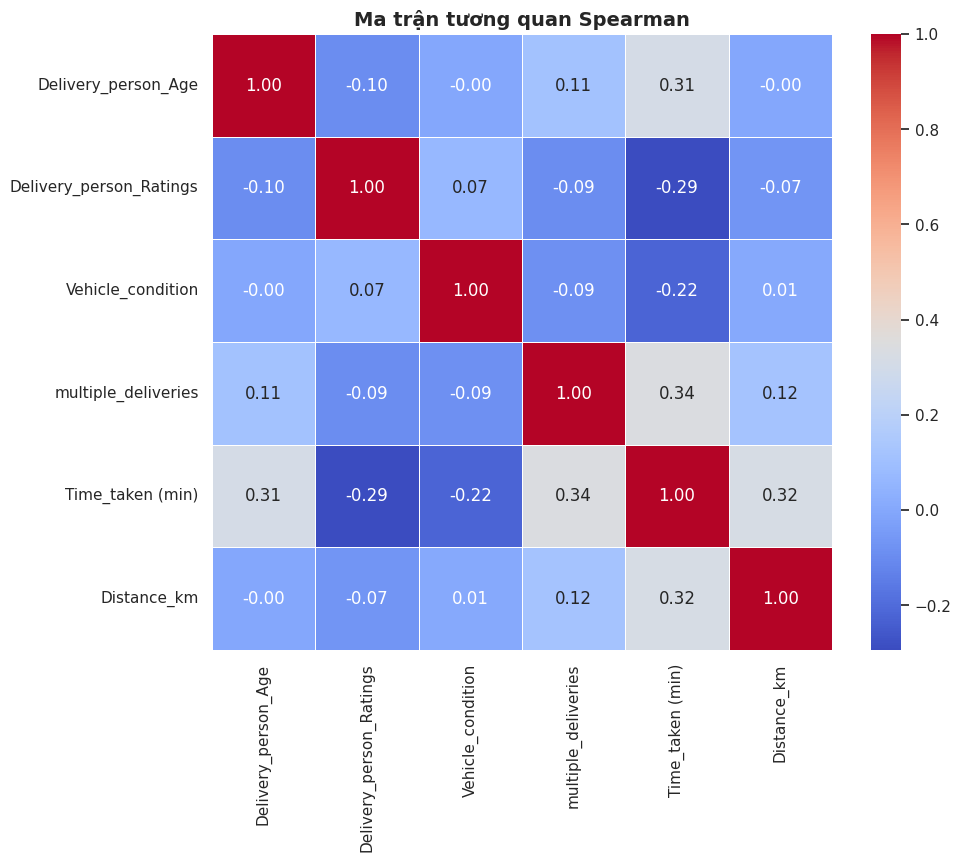

In [ ]:

corr_cols =[
    'Delivery_person_Age',
    'Delivery_person_Ratings',
    'Vehicle_condition',
    'multiple_deliveries',
    'Time_taken (min)',
    'Distance_km'
]

# THÊM method='spearman'
corr_matrix = df[corr_cols].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Ma trận tương quan Spearman', fontsize=14, fontweight='bold')
plt.show()